# 03 - Neural Network Experiments

**Goal:** Train fully connected networks in Keras and measure the effect of each technique from Courses 1-2 (depth, regularization, optimizers, batch normalization, learning rate decay, hyperparameter search).

**Rules for a fair comparison**
- Same processed data as the baselines (`02_baselines`), same seed at the start of every experiment.
- Everything is evaluated on the **dev set**. The test set is used only once, at the end.
- Main metric: **macro F1** and per-class recall. Reference points from notebook 02: Logistic Regression 0.53, Random Forest 0.92.

## 0. Setup

In [18]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

%load_ext autoreload
%autoreload 2
from src.data import load_processed
from src.models import build_model
from src.train import train_model, plot_history, predict_classes
from src.experiments import run_experiment
from src.evaluate import evaluate, plot_confusion

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
SEED = 42
tf.keras.utils.set_random_seed(SEED)

## 1. Load the processed data

The arrays were saved by notebook 02 (labels 0-6, numeric features already standardized with training statistics).

In [9]:
data = load_processed()
X_train, y_train = data["X_train"], data["y_train"]
X_dev, y_dev = data["X_dev"], data["y_dev"]
X_test, y_test = data["X_test"], data["y_test"]

In [10]:
for name, arr in data.items():
    print(f"{name:8} shape={arr.shape} dtype={arr.dtype}")

print("classes:", np.unique(y_train))

X_train  shape=(464809, 54) dtype=float32
X_dev    shape=(58101, 54) dtype=float32
X_test   shape=(58102, 54) dtype=float32
y_train  shape=(464809,) dtype=int64
y_dev    shape=(58101,) dtype=int64
y_test   shape=(58102,) dtype=int64
classes: [0 1 2 3 4 5 6]


## 2. First model: one hidden layer

Architecture: 54 inputs -> Dense(64, ReLU, He initialization) -> Dense(7, softmax). It has 3,975 parameters.

Training setup (kept the same for the first experiments): Adam (learning rate 0.001), mini-batches of 512, 20 epochs, `sparse_categorical_crossentropy` loss (labels are integers 0-6).

In [11]:
model = build_model([64])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │         3,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,975 (15.53 KB)

 Trainable params: 3,975 (15.53 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Experiments

`results` collects the dev metrics of every experiment, to build the final comparison table.

In [19]:
results = []

Epoch 1/20
908/908 - 39s - 43ms/step - accuracy: 0.7055 - loss: 0.7299 - val_accuracy: 0.7452 - val_loss: 0.6039
Epoch 2/20
908/908 - 4s - 4ms/step - accuracy: 0.7525 - loss: 0.5799 - val_accuracy: 0.7618 - val_loss: 0.5614
Epoch 3/20
908/908 - 3s - 3ms/step - accuracy: 0.7667 - loss: 0.5467 - val_accuracy: 0.7739 - val_loss: 0.5350
Epoch 4/20
908/908 - 3s - 4ms/step - accuracy: 0.7769 - loss: 0.5244 - val_accuracy: 0.7821 - val_loss: 0.5164
Epoch 5/20
908/908 - 5s - 6ms/step - accuracy: 0.7838 - loss: 0.5081 - val_accuracy: 0.7873 - val_loss: 0.5021
Epoch 6/20
908/908 - 3s - 3ms/step - accuracy: 0.7890 - loss: 0.4954 - val_accuracy: 0.7916 - val_loss: 0.4907
Epoch 7/20
908/908 - 3s - 4ms/step - accuracy: 0.7935 - loss: 0.4853 - val_accuracy: 0.7943 - val_loss: 0.4816
Epoch 8/20
908/908 - 3s - 4ms/step - accuracy: 0.7966 - loss: 0.4771 - val_accuracy: 0.7973 - val_loss: 0.4743
Epoch 9/20
908/908 - 3s - 3ms/step - accuracy: 0.7996 - loss: 0.4701 - val_accuracy: 0.8011 - val_loss: 0.4679

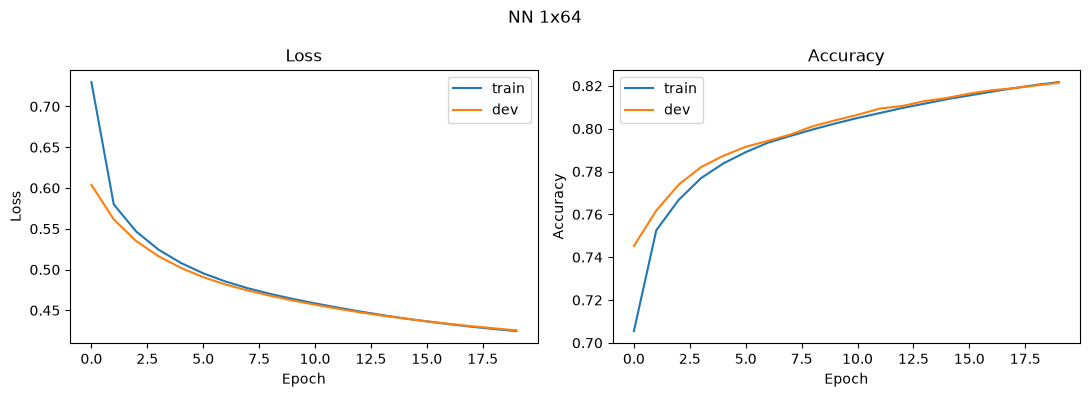

=== NN 1x64 ===
              precision    recall  f1-score   support

           0       0.84      0.77      0.81     21184
           1       0.82      0.89      0.85     28330
           2       0.80      0.83      0.82      3575
           3       0.77      0.66      0.71       275
           4       0.76      0.36      0.49       950
           5       0.66      0.59      0.62      1736
           6       0.85      0.82      0.83      2051

    accuracy                           0.82     58101
   macro avg       0.78      0.70      0.73     58101
weighted avg       0.82      0.82      0.82     58101



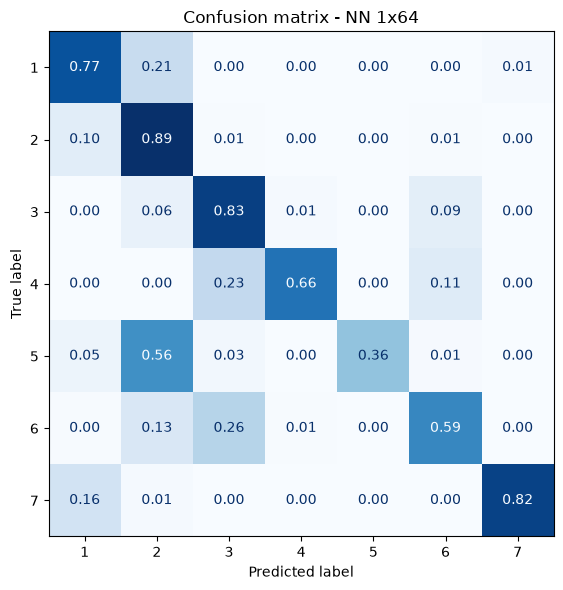

<Sequential name=sequential_4, built=True>

In [20]:
run_experiment("NN 1x64", [64], data, results)

**Observations (1 hidden layer, 64 units)**
- Train and dev curves are almost identical (train accuracy 0.822, dev accuracy 0.821), so there is no overfitting.
- Both are still improving at epoch 20: the model is **underfitting** and has not converged.
- Macro F1 is about 0.73: much better than Logistic Regression (0.53), but far from Random Forest (0.92).
- The training error (about 18%) is much higher than the Random Forest error (about 4.6%), so the main problem is **high bias**. Regularization will not help yet. The model needs more capacity or more training.
- Confusion matrix (original class names 1-7): class 5 is the hardest (recall 0.36, and 56% of it is predicted as class 2). Class 6 has recall 0.59 (26% predicted as class 3) and class 4 has recall 0.66 (23% predicted as class 3). Classes 1 and 2 are mixed in both directions (21% of class 1 predicted as class 2).
- Compared with Logistic Regression, all small classes improved, so the hidden layer is learning non-linear patterns.

Note: the classification report uses labels 0-6 (`Cover_Type` minus 1).

### Experiment 2: deeper and wider networks

Since the first model underfits, I increase the capacity: 2, 3 and 4 hidden layers with more neurons. Everything else stays the same (Adam, learning rate 0.001, batch size 512, 20 epochs, same seed).

Epoch 1/20
908/908 - 7s - 8ms/step - accuracy: 0.7422 - loss: 0.6183 - val_accuracy: 0.7806 - val_loss: 0.5196
Epoch 2/20
908/908 - 4s - 5ms/step - accuracy: 0.7935 - loss: 0.4871 - val_accuracy: 0.8049 - val_loss: 0.4618
Epoch 3/20
908/908 - 5s - 5ms/step - accuracy: 0.8139 - loss: 0.4424 - val_accuracy: 0.8211 - val_loss: 0.4265
Epoch 4/20
908/908 - 4s - 5ms/step - accuracy: 0.8283 - loss: 0.4119 - val_accuracy: 0.8317 - val_loss: 0.4019
Epoch 5/20
908/908 - 4s - 5ms/step - accuracy: 0.8384 - loss: 0.3897 - val_accuracy: 0.8394 - val_loss: 0.3848
Epoch 6/20
908/908 - 5s - 5ms/step - accuracy: 0.8461 - loss: 0.3723 - val_accuracy: 0.8457 - val_loss: 0.3704
Epoch 7/20
908/908 - 4s - 5ms/step - accuracy: 0.8524 - loss: 0.3580 - val_accuracy: 0.8513 - val_loss: 0.3591
Epoch 8/20
908/908 - 4s - 5ms/step - accuracy: 0.8574 - loss: 0.3462 - val_accuracy: 0.8546 - val_loss: 0.3496
Epoch 9/20
908/908 - 5s - 6ms/step - accuracy: 0.8622 - loss: 0.3363 - val_accuracy: 0.8579 - val_loss: 0.3422
E

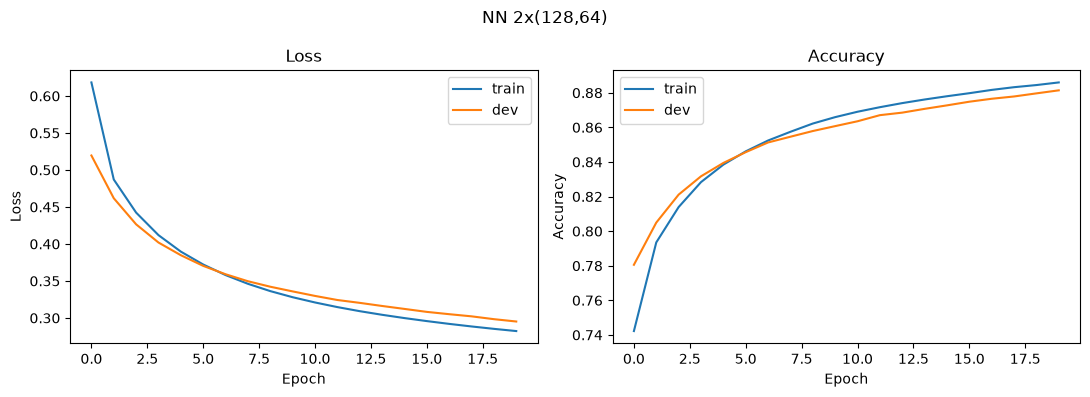

=== NN 2x(128,64) ===
              precision    recall  f1-score   support

           0       0.89      0.88      0.88     21184
           1       0.90      0.90      0.90     28330
           2       0.78      0.95      0.86      3575
           3       0.90      0.62      0.73       275
           4       0.78      0.64      0.70       950
           5       0.76      0.62      0.69      1736
           6       0.90      0.89      0.90      2051

    accuracy                           0.88     58101
   macro avg       0.84      0.79      0.81     58101
weighted avg       0.88      0.88      0.88     58101



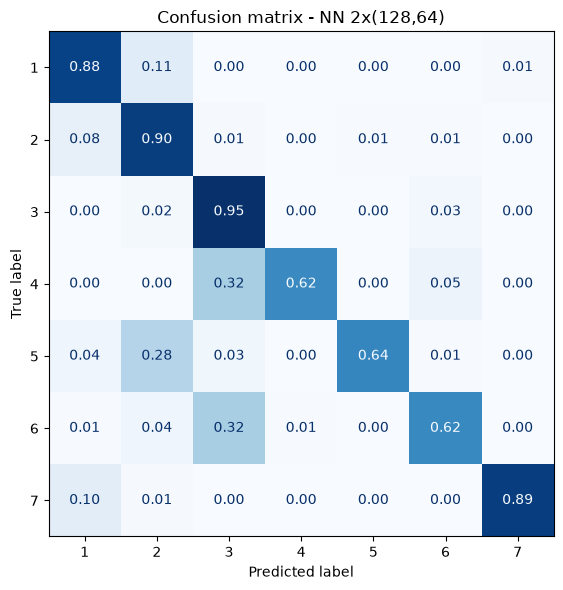

<Sequential name=sequential_5, built=True>

In [21]:
run_experiment("NN 2x(128,64)", [128, 64], data, results)

Epoch 1/20
908/908 - 9s - 10ms/step - accuracy: 0.7720 - loss: 0.5414 - val_accuracy: 0.8155 - val_loss: 0.4415
Epoch 2/20
908/908 - 6s - 7ms/step - accuracy: 0.8317 - loss: 0.4015 - val_accuracy: 0.8434 - val_loss: 0.3765
Epoch 3/20
908/908 - 6s - 6ms/step - accuracy: 0.8540 - loss: 0.3515 - val_accuracy: 0.8579 - val_loss: 0.3427
Epoch 4/20
908/908 - 6s - 6ms/step - accuracy: 0.8676 - loss: 0.3204 - val_accuracy: 0.8689 - val_loss: 0.3183
Epoch 5/20
908/908 - 6s - 6ms/step - accuracy: 0.8776 - loss: 0.2978 - val_accuracy: 0.8764 - val_loss: 0.3019
Epoch 6/20
908/908 - 6s - 7ms/step - accuracy: 0.8856 - loss: 0.2798 - val_accuracy: 0.8826 - val_loss: 0.2883
Epoch 7/20
908/908 - 6s - 6ms/step - accuracy: 0.8918 - loss: 0.2654 - val_accuracy: 0.8862 - val_loss: 0.2773
Epoch 8/20
908/908 - 10s - 11ms/step - accuracy: 0.8969 - loss: 0.2533 - val_accuracy: 0.8909 - val_loss: 0.2670
Epoch 9/20
908/908 - 6s - 6ms/step - accuracy: 0.9012 - loss: 0.2433 - val_accuracy: 0.8941 - val_loss: 0.258

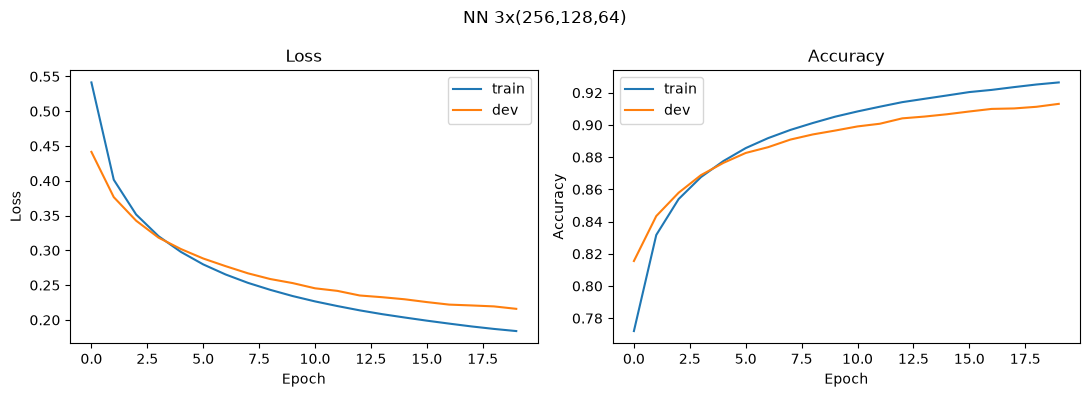

=== NN 3x(256,128,64) ===
              precision    recall  f1-score   support

           0       0.94      0.88      0.91     21184
           1       0.92      0.94      0.93     28330
           2       0.82      0.96      0.88      3575
           3       0.90      0.66      0.76       275
           4       0.85      0.77      0.81       950
           5       0.82      0.79      0.81      1736
           6       0.87      0.97      0.92      2051

    accuracy                           0.91     58101
   macro avg       0.87      0.85      0.86     58101
weighted avg       0.91      0.91      0.91     58101



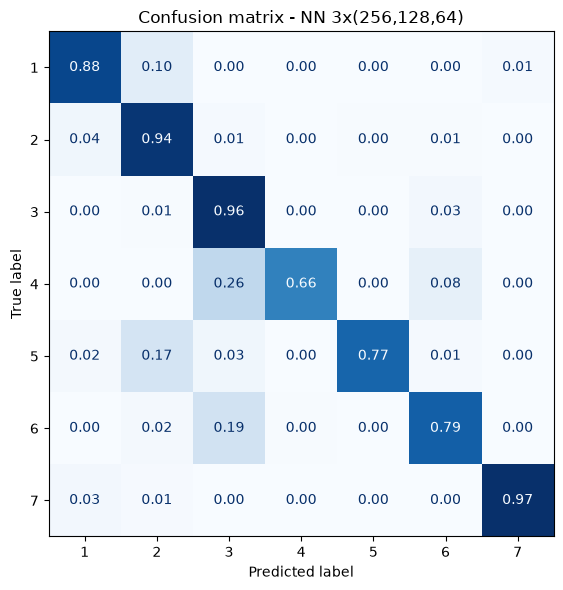

<Sequential name=sequential_6, built=True>

In [22]:
run_experiment("NN 3x(256,128,64)", [256, 128, 64], data, results)

Epoch 1/20
908/908 - 16s - 18ms/step - accuracy: 0.7925 - loss: 0.4908 - val_accuracy: 0.8392 - val_loss: 0.3894
Epoch 2/20
908/908 - 14s - 15ms/step - accuracy: 0.8529 - loss: 0.3522 - val_accuracy: 0.8679 - val_loss: 0.3212
Epoch 3/20
908/908 - 21s - 23ms/step - accuracy: 0.8778 - loss: 0.2963 - val_accuracy: 0.8846 - val_loss: 0.2858
Epoch 4/20
908/908 - 20s - 22ms/step - accuracy: 0.8935 - loss: 0.2610 - val_accuracy: 0.8929 - val_loss: 0.2648
Epoch 5/20
908/908 - 21s - 23ms/step - accuracy: 0.9044 - loss: 0.2363 - val_accuracy: 0.8995 - val_loss: 0.2498
Epoch 6/20
908/908 - 14s - 15ms/step - accuracy: 0.9122 - loss: 0.2175 - val_accuracy: 0.9071 - val_loss: 0.2316
Epoch 7/20
908/908 - 13s - 14ms/step - accuracy: 0.9180 - loss: 0.2027 - val_accuracy: 0.9127 - val_loss: 0.2176
Epoch 8/20
908/908 - 13s - 15ms/step - accuracy: 0.9231 - loss: 0.1910 - val_accuracy: 0.9166 - val_loss: 0.2075
Epoch 9/20
908/908 - 13s - 14ms/step - accuracy: 0.9274 - loss: 0.1809 - val_accuracy: 0.9194 - 

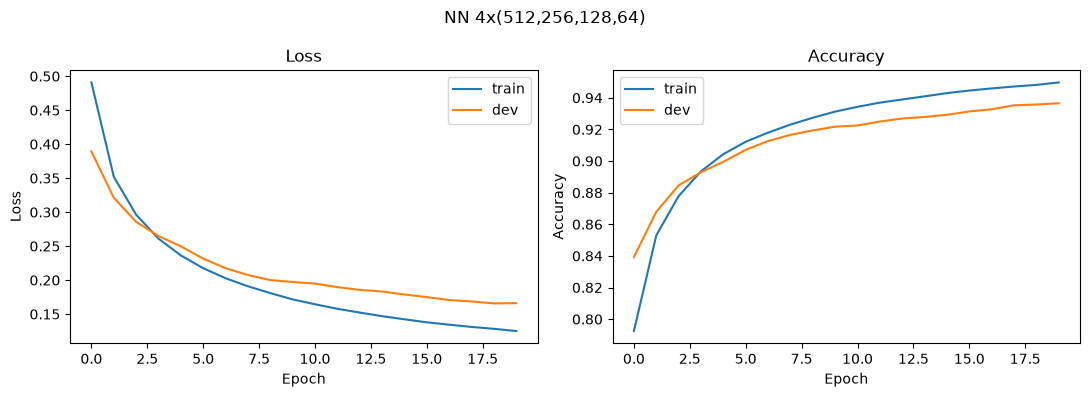

=== NN 4x(512,256,128,64) ===
              precision    recall  f1-score   support

           0       0.95      0.92      0.93     21184
           1       0.94      0.96      0.95     28330
           2       0.89      0.97      0.93      3575
           3       0.91      0.79      0.85       275
           4       0.87      0.81      0.84       950
           5       0.90      0.85      0.87      1736
           6       0.90      0.97      0.93      2051

    accuracy                           0.94     58101
   macro avg       0.91      0.89      0.90     58101
weighted avg       0.94      0.94      0.94     58101



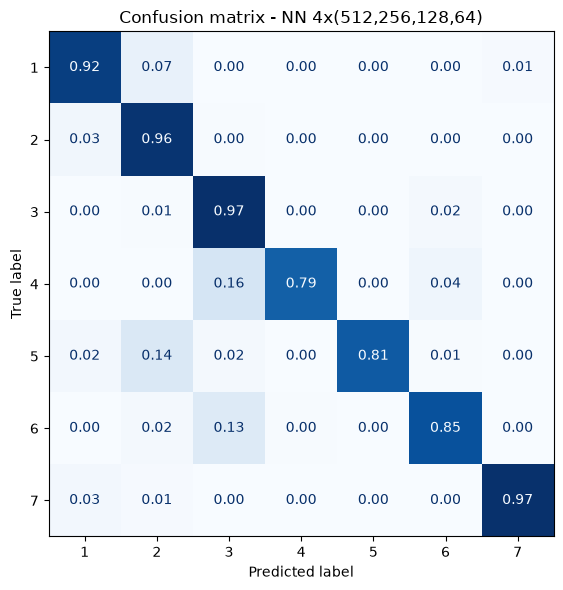

<Sequential name=sequential_7, built=True>

In [23]:
run_experiment("NN 4x(512,256,128,64)", [512, 256, 128, 64], data, results)

**Observations (capacity experiments, 20 epochs each)**
- More capacity improved the dev macro F1 at every step: 0.73 -> 0.81 -> 0.86 -> 0.90. Dev accuracy went from 0.82 to 0.94.
- Training accuracy also increased (0.82 -> 0.95), so the main problem was high bias, and a bigger network fixed most of it.
- The small classes benefited the most. For example, the recall of class 5 (the hardest) went from 0.36 to 0.81.
- A gap between train and dev appears and grows with the network size (about 0.4 points for 2 layers, 1.0 for 3 layers and 1.1 for 4 layers).
- The 4-layer model is still improving at epoch 20, so I train it longer.

### Experiment 3: train longer

The best architecture so far (4 hidden layers) trained for 60 epochs instead of 20.

Epoch 1/60
908/908 - 17s - 18ms/step - accuracy: 0.7925 - loss: 0.4908 - val_accuracy: 0.8392 - val_loss: 0.3894
Epoch 2/60
908/908 - 15s - 16ms/step - accuracy: 0.8529 - loss: 0.3522 - val_accuracy: 0.8679 - val_loss: 0.3212
Epoch 3/60
908/908 - 13s - 15ms/step - accuracy: 0.8778 - loss: 0.2963 - val_accuracy: 0.8846 - val_loss: 0.2858
Epoch 4/60
908/908 - 20s - 22ms/step - accuracy: 0.8935 - loss: 0.2610 - val_accuracy: 0.8929 - val_loss: 0.2648
Epoch 5/60
908/908 - 13s - 14ms/step - accuracy: 0.9044 - loss: 0.2363 - val_accuracy: 0.8995 - val_loss: 0.2498
Epoch 6/60
908/908 - 13s - 14ms/step - accuracy: 0.9122 - loss: 0.2175 - val_accuracy: 0.9071 - val_loss: 0.2316
Epoch 7/60
908/908 - 14s - 15ms/step - accuracy: 0.9180 - loss: 0.2027 - val_accuracy: 0.9127 - val_loss: 0.2176
Epoch 8/60
908/908 - 14s - 15ms/step - accuracy: 0.9231 - loss: 0.1910 - val_accuracy: 0.9166 - val_loss: 0.2075
Epoch 9/60
908/908 - 20s - 22ms/step - accuracy: 0.9274 - loss: 0.1809 - val_accuracy: 0.9194 - 

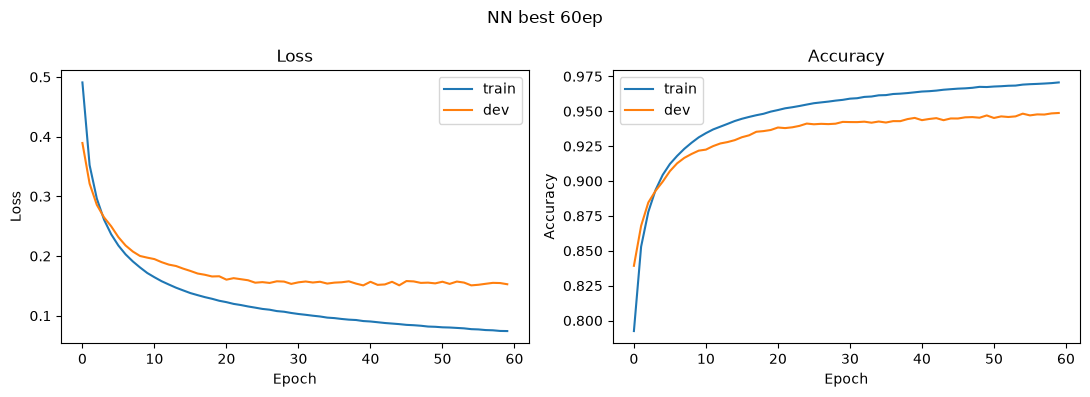

=== NN best 60ep ===
              precision    recall  f1-score   support

           0       0.95      0.95      0.95     21184
           1       0.96      0.96      0.96     28330
           2       0.93      0.96      0.95      3575
           3       0.90      0.82      0.86       275
           4       0.87      0.85      0.86       950
           5       0.91      0.88      0.90      1736
           6       0.95      0.95      0.95      2051

    accuracy                           0.95     58101
   macro avg       0.92      0.91      0.92     58101
weighted avg       0.95      0.95      0.95     58101



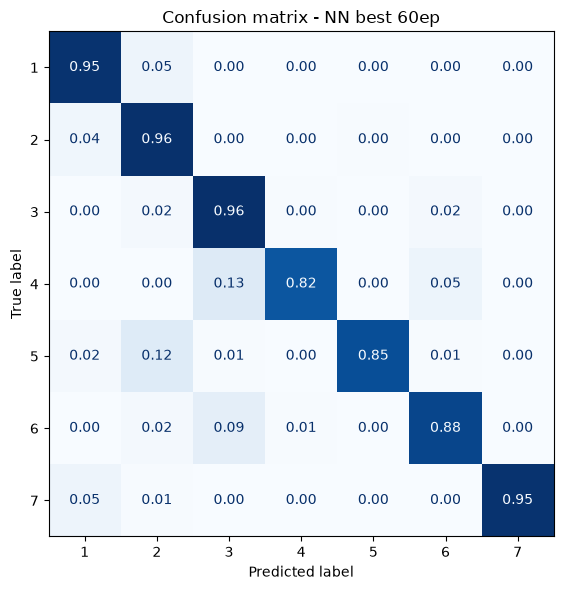

<Sequential name=sequential_8, built=True>

In [24]:
run_experiment("NN best 60ep", [512, 256, 128, 64], data, results, epochs=60)

**Observations (4 hidden layers, 60 epochs)**
- Dev macro F1 rose from 0.90 to 0.916 and dev accuracy to 0.949, very close to Random Forest (macro F1 0.923, accuracy 0.954).
- The curves show the start of **overfitting**: the train loss keeps falling (0.074 at epoch 60) but the dev loss stops improving after about epoch 20 (around 0.155). The accuracy gap is 1.6 points (train 0.964, dev 0.949).
- The training error (3.6%) is already lower than the Random Forest dev error (4.6%), so bias is no longer the main problem. The remaining gap is **variance**, which is what regularization is for.
- Every class has recall of at least 0.82. The hardest are class 4 (0.82, 13% predicted as class 3), class 5 (0.85, 12% predicted as class 2) and class 6 (0.88, 9% predicted as class 3). Class 5 is better than with Random Forest (0.85 vs 0.77), and class 4 is similar (0.82 vs 0.83).

## 4. Comparison table

`train_acc` is the accuracy on the full training set after training, and `accuracy` / `macro_f1` are on the dev set. The gap between them shows how much the model overfits.

In [25]:
results_df = pd.DataFrame(results)
results_df

,model,accuracy,macro_f1,params,train_acc
0,NN 1x64,0.821414,0.733075,3975,0.822314
1,"NN 2x(128,64)",0.881413,0.808019,15751,0.885615
2,"NN 3x(256,128,64)",0.913100,0.859446,55687,0.922659
3,"NN 4x(512,256,128,64)",0.936559,0.900783,201095,0.947830
4,NN best 60ep,0.948744,0.916265,201095,0.964471


In [26]:
pd.DataFrame(results).to_csv("../results/nn_results.csv", index=False)

**Takeaways so far**
- Capacity was the first bottleneck: going from 1 hidden layer to 4 raised the dev macro F1 from 0.73 to 0.90 (0.92 with more epochs).
- The 4-layer network (60 epochs) is close to Random Forest (0.916 vs 0.923 macro F1) but does not beat it yet.
- The train/dev gap and the flat dev loss show overfitting. This network (4 layers, 60 epochs) is the **reference model** for the next experiments: L2 and Dropout, then optimizers, batch normalization and learning rate decay.